In [3]:
%matplotlib inline
from pathlib import Path
import os
import joblib
import tqdm


import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
# from ydata_profiling import ProfileReport
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.metrics import (confusion_matrix, balanced_accuracy_score, accuracy_score, 
classification_report, RocCurveDisplay, ConfusionMatrixDisplay, recall_score)
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.utils.validation import check_is_fitted, check_X_y, check_array
from sklearn.utils.class_weight import compute_class_weight
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

from imblearn.over_sampling import SMOTENC, RandomOverSampler
from imblearn.metrics import classification_report_imbalanced, macro_averaged_mean_absolute_error
from imblearn.pipeline import Pipeline

from lightgbm import LGBMClassifier
import xgboost as xgb

Cargamos los datos, revisamos inicialmente el numero de datos faltantes y duplicados y se eliminan del set de datos

In [4]:
data = pd.read_csv("data.csv", skipinitialspace=True)
data = data.drop(columns=["Unnamed: 0"])

In [5]:
data.isna().sum().sum()

np.int64(261)

In [6]:
data.duplicated().sum()

np.int64(0)

In [7]:
n_inicial = len(data)
data = data.dropna()
n_final = len(data)

In [8]:
print(f"% perdido: {(n_inicial - n_final)/n_final * 100:.2f} %")

% perdido: 2.44 %


Ahora, miramos los comportamientos de los datos numericos para ver algun patron poco habitual o comportamientos lineales en caso de correlaciones, asi como la distrbucion de los mismos datos}

/var/folders/28/306ycwnd0js93qjmlz4_s2gc0000gn/T/ipykernel_13592/891162425.py:6: UserWarning: To output multiple subplots, the figure containing the passed axes is being cleared.
  matrix = pd.plotting.scatter_matrix(df, figsize=(10, 10), diagonal="hist", ax=ax)


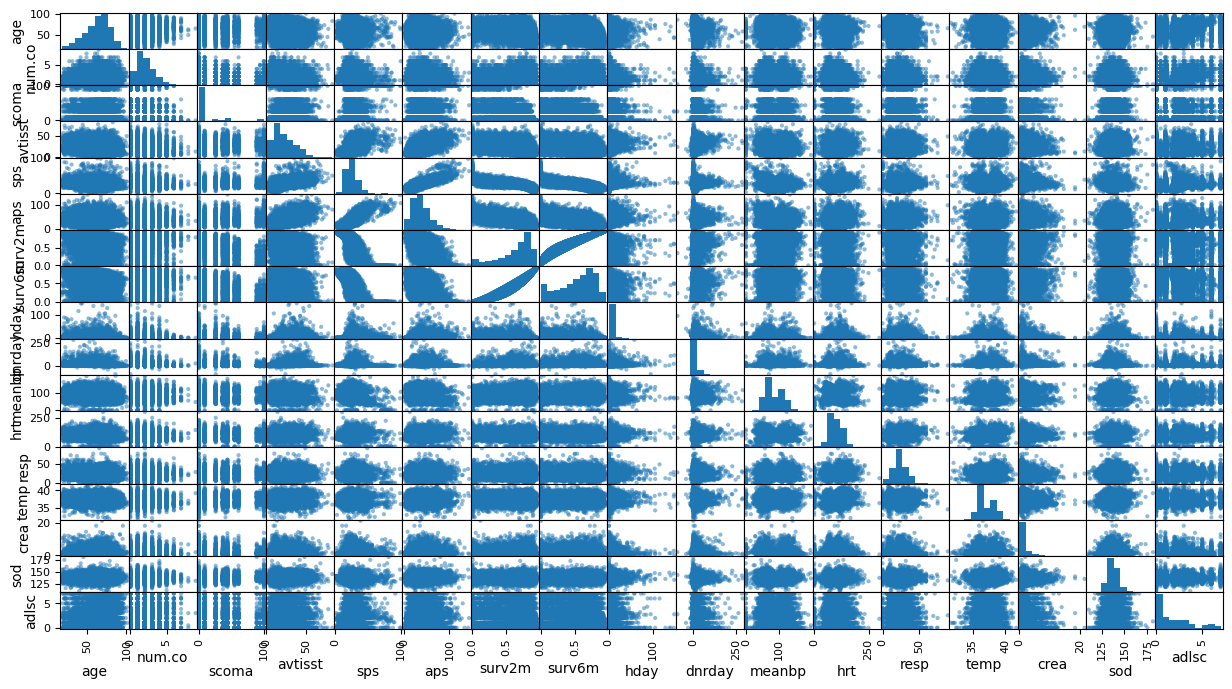

In [9]:
df = data.select_dtypes(include="number")

df = df.drop(columns=[x for x in df if np.array_equal(df[x].unique(), np.array([0, 1]))])
fig, ax = plt.subplots(figsize=(15, 8))

matrix = pd.plotting.scatter_matrix(df, figsize=(10, 10), diagonal="hist", ax=ax)
plt.show()

De lo que se puede ver las variables survm6m y surv2 se encuentran correlacionadas, las quitamos del modelo y probando se obtuvo que el modelo con las variables correlacionadas es mejor en todas las metricas, mostrando que una de estas variables si aportan informacion relevante en la prediccion por lo que decidimos manejar el modelo con todas las variables

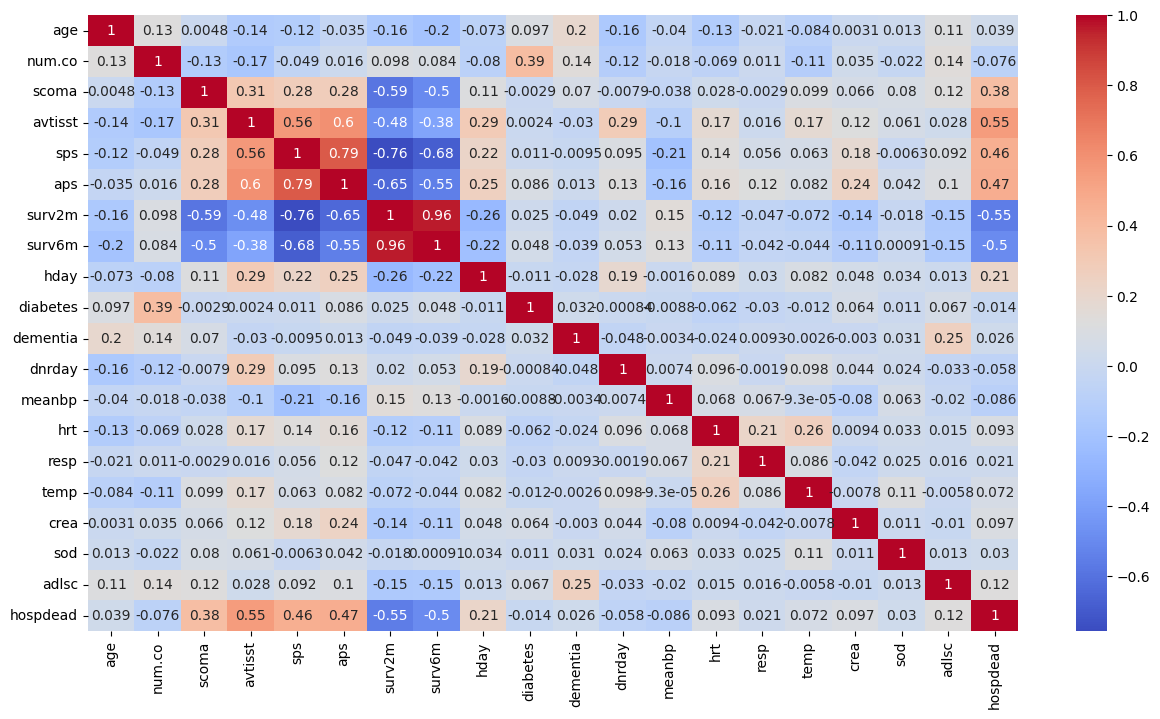

In [44]:
fig, ax = plt.subplots(figsize=(15, 8))

sns.heatmap(df.corr(numeric_only=True),annot=True, cmap="coolwarm", ax=ax)
plt.show()

array([[<Axes: title={'center': 'age'}>,
        <Axes: title={'center': 'num.co'}>,
        <Axes: title={'center': 'scoma'}>,
        <Axes: title={'center': 'avtisst'}>],
       [<Axes: title={'center': 'sps'}>, <Axes: title={'center': 'aps'}>,
        <Axes: title={'center': 'surv2m'}>,
        <Axes: title={'center': 'surv6m'}>],
       [<Axes: title={'center': 'hday'}>,
        <Axes: title={'center': 'diabetes'}>,
        <Axes: title={'center': 'dementia'}>,
        <Axes: title={'center': 'dnrday'}>],
       [<Axes: title={'center': 'meanbp'}>,
        <Axes: title={'center': 'hrt'}>,
        <Axes: title={'center': 'resp'}>,
        <Axes: title={'center': 'temp'}>],
       [<Axes: title={'center': 'crea'}>,
        <Axes: title={'center': 'sod'}>,
        <Axes: title={'center': 'adlsc'}>,
        <Axes: title={'center': 'hospdead'}>]], dtype=object)

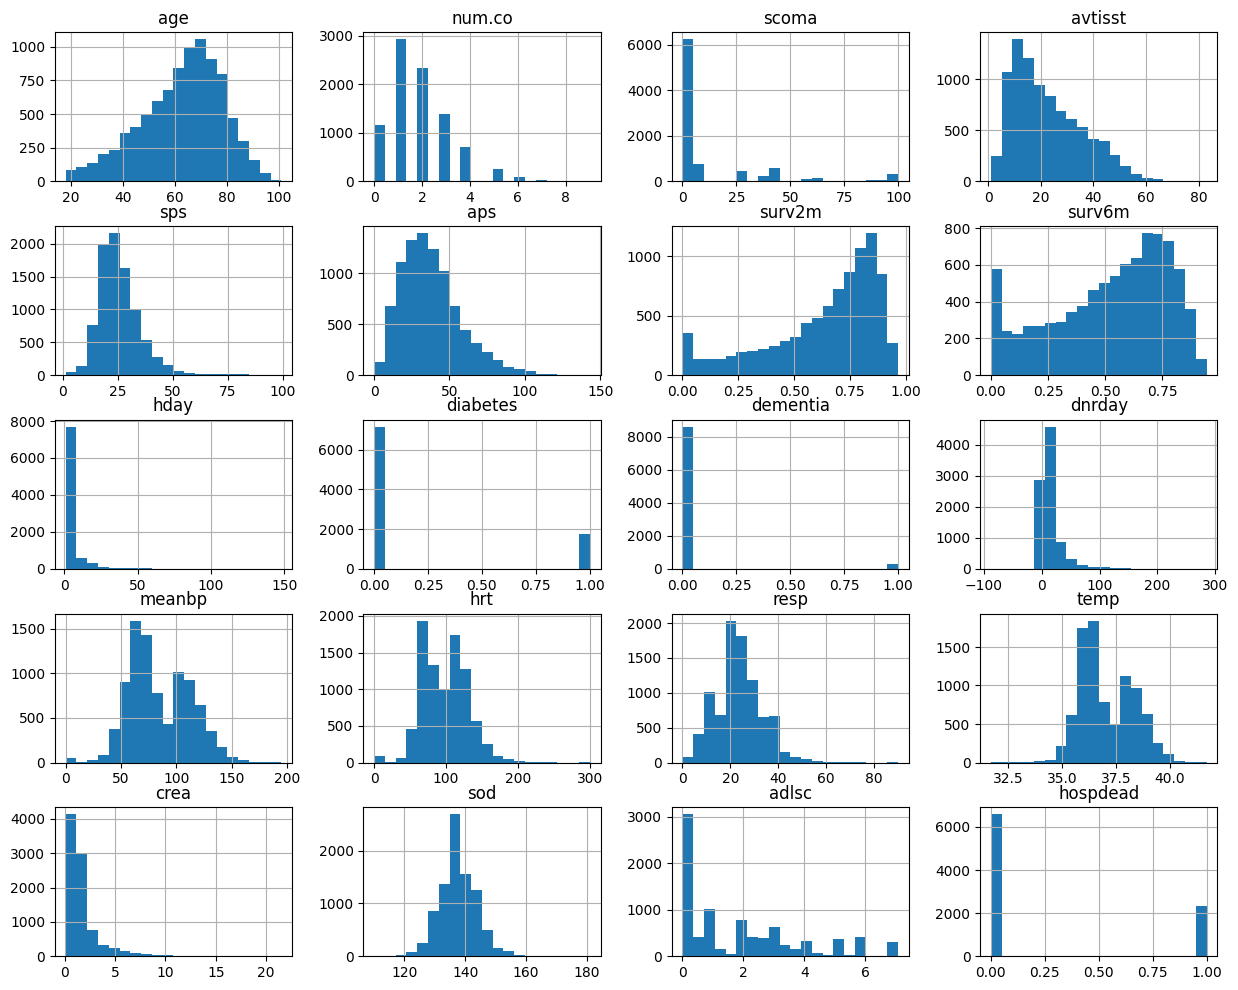

In [69]:
data.hist(figsize=(15, 12), bins=20)

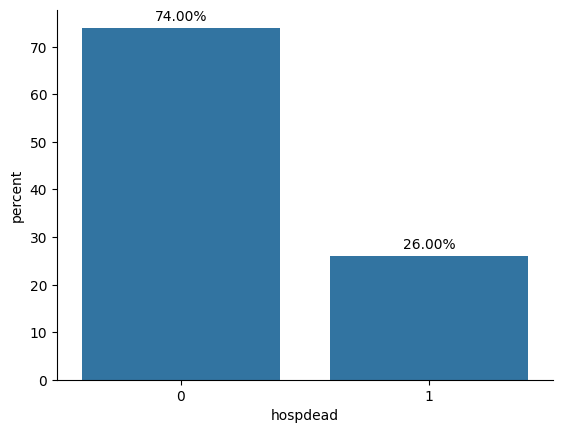

In [82]:
fig, ax = plt.subplots()

sns.countplot(data=data, x="hospdead", stat="percent", ax=ax)

for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%.2f%%", padding=3)

ax.spines[["top", "right"]].set_visible(False)

plt.show()

In [12]:
os.path.exists("grid_search/data/X_test.joblib")

True

data already exists, not re-generating


<Axes: ylabel='Frequency'>

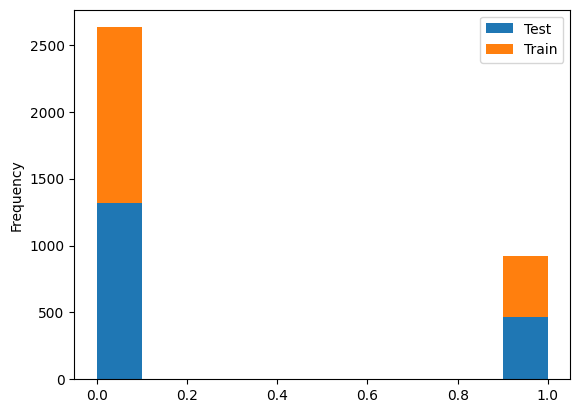

In [14]:
y = data["hospdead"]
X = data.drop(columns="hospdead")
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2,random_state=42,stratify=y)


data_prefix = "grid_search/data"
os.makedirs(data_prefix,exist_ok=True)

if os.path.exists(data_prefix+"/X_train.joblib"):
    print("data already exists, not re-generating")
else:
    joblib.dump(X_train, f"{data_prefix}/X_train.joblib")
    joblib.dump(y_train, f"{data_prefix}/y_train.joblib")
    joblib.dump(X_test, f"{data_prefix}/X_test.joblib")
    joblib.dump(y_test, f"{data_prefix}/y_test.joblib")

pd.DataFrame({"Test": y_test.to_numpy(), "Train": y_test.to_numpy()}).plot.hist(stacked=True)

In [15]:
cols_num = X_train.select_dtypes(include="number").columns
cols_cat = X_train.select_dtypes(include=["object", "string", "category", "bool"]).columns

procesar_num = Pipeline([
    ("escalar", StandardScaler()) ])

procesar_cat = Pipeline([
    ("codificar", OneHotEncoder(handle_unknown="ignore"))])

preprocesador = ColumnTransformer([
    ("numericas", procesar_num, cols_num),
    ("categoricas", procesar_cat, cols_cat)])
modelo = Pipeline([("preprocesar", preprocesador),("lightgbm", LGBMClassifier(is_unbalance=True, objective="binary", verbose=-1))])
modelos = {}

In [16]:
def mostrar_resultados(y_test, y_pred, title, prefix="results"):
    os.makedirs(prefix,exist_ok=True)
    etiquetas = ["No enfermo", "Enfermo"]
    matriz = confusion_matrix(y_test,y_pred,labels=np.arange(len(etiquetas)), normalize="pred") * 100
    
    print("Test balanced accuracy:", balanced_accuracy_score(y_test, y_pred))
    print(" Trace", np.trace(matriz))
    print(" Matriz de confusión")
    fig, ax = plt.subplots(figsize=(8, 4))
    
    disp = ConfusionMatrixDisplay(confusion_matrix=matriz, display_labels=etiquetas)
    
    disp.plot(ax=ax, cmap="Blues")
    ax.set_xlabel("Valor predicho")
    ax.set_ylabel("Valor real")
    ax.set_title(f"Matriz de confusión {title}")
    
    fig.tight_layout()
    plt.show()

    fig.savefig(f"{prefix}/grafica_{title}.png", dpi=300, bbox_inches="tight")
    fig.savefig(f"{prefix}/grafica_{title}.pdf", bbox_inches="tight")

    plt.close(fig)
    
    print("Reporte de la clasificación")
    print(classification_report(y_test,y_pred,digits=3,zero_division=0))
    print("Reporte de clasificación desbalanceado")
    print(classification_report_imbalanced(y_test, y_pred, target_names=etiquetas))

In [17]:
X_train = joblib.load(f"{data_prefix}/X_train.joblib")
y_train = joblib.load(f"{data_prefix}/y_train.joblib")
y_test = joblib.load(f"{data_prefix}/y_test.joblib")
X_test = joblib.load(f"{data_prefix}/X_test.joblib")

In [18]:
modelo_inicial = modelo.fit(X_train, y_train)
y_pred = modelo.predict(X_test)
modelos["Crudo"] = modelo_inicial

Test balanced accuracy: 0.8840034079395782
 Trace 171.3000670334419
 Matriz de confusión


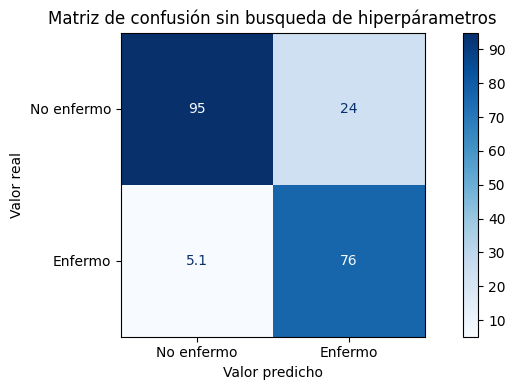

Reporte de la clasificación
              precision    recall  f1-score   support

           0      0.949     0.907     0.927      1316
           1      0.764     0.861     0.810       462

    accuracy                          0.895      1778
   macro avg      0.857     0.884     0.869      1778
weighted avg      0.901     0.895     0.897      1778

Reporte de clasificación desbalanceado
                   pre       rec       spe        f1       geo       iba       sup

 No enfermo       0.95      0.91      0.86      0.93      0.88      0.78      1316
    Enfermo       0.76      0.86      0.91      0.81      0.88      0.78       462

avg / total       0.90      0.89      0.87      0.90      0.88      0.78      1778



In [19]:
mostrar_resultados(y_test, y_pred, "sin busqueda de hiperpárametros")

In [22]:
from glob import glob

In [26]:
modelos = {}
for file in glob("grid_search/results/*.joblib"):
    modelos[os.path.basename(file).replace(".joblib","")] = joblib.load(file)

In [28]:
#folder = Path("grid_search/results")
#modelos = {}

#for file in folder.iterdir():
#    if file.suffix == ".joblib":
#        modelos[file.stem] = joblib.load(file)
        
#y_test = joblib.load(f"{data_prefix}/y_test.joblib")
#X_test = joblib.load(f"{data_prefix}/X_test.joblib")

Test balanced accuracy: 0.8889195910472506
 Trace 171.1152547725205
 Matriz de confusión


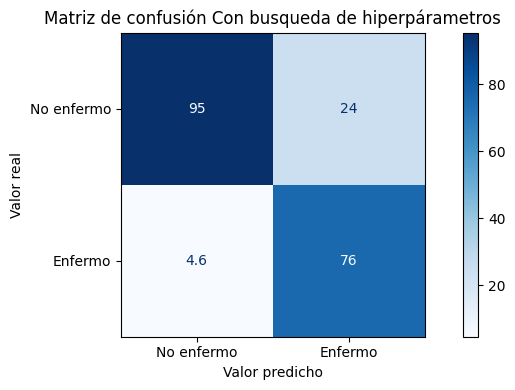

Reporte de la clasificación
              precision    recall  f1-score   support

           0      0.954     0.901     0.927      1316
           1      0.757     0.877     0.812       462

    accuracy                          0.895      1778
   macro avg      0.856     0.889     0.870      1778
weighted avg      0.903     0.895     0.897      1778

Reporte de clasificación desbalanceado
                   pre       rec       spe        f1       geo       iba       sup

 No enfermo       0.95      0.90      0.88      0.93      0.89      0.79      1316
    Enfermo       0.76      0.88      0.90      0.81      0.89      0.79       462

avg / total       0.90      0.89      0.88      0.90      0.89      0.79      1778



In [29]:
y_pred = modelos["LGBM_none_best"].predict(X_test)
mostrar_resultados(y_test, y_pred, "Con busqueda de hiperpárametros")

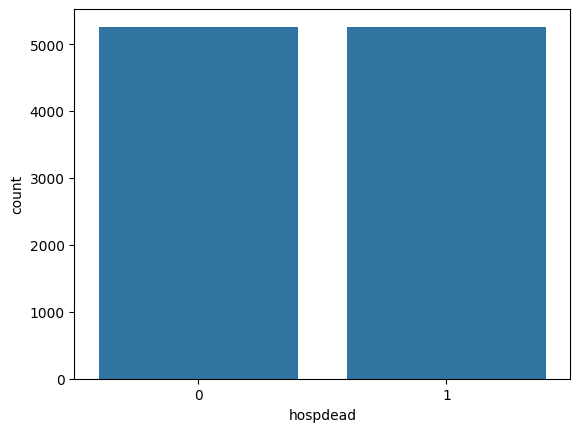

In [31]:
X_resampled, y_resampled = SMOTENC(categorical_features=X.select_dtypes(exclude="number").columns.tolist(), sampling_strategy=1, random_state=42).fit_resample(X_train, y_train)
sns.countplot(x=y_resampled)
plt.show()
#print(*sorted(Counter(y_resampled).items()), sep="\n")

Test balanced accuracy: 0.8729045776918117
 Trace 175.4365359277054
 Matriz de confusión


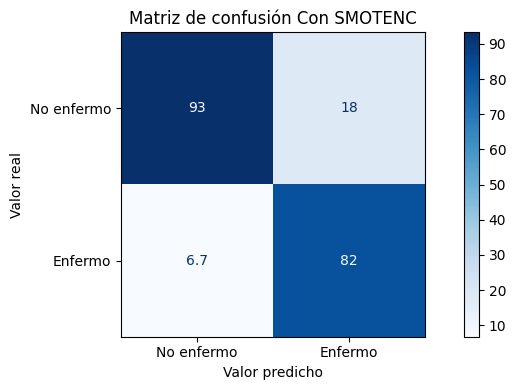

Reporte de la clasificación
              precision    recall  f1-score   support

           0      0.933     0.938     0.936      1316
           1      0.822     0.807     0.814       462

    accuracy                          0.904      1778
   macro avg      0.877     0.873     0.875      1778
weighted avg      0.904     0.904     0.904      1778

Reporte de clasificación desbalanceado
                   pre       rec       spe        f1       geo       iba       sup

 No enfermo       0.93      0.94      0.81      0.94      0.87      0.77      1316
    Enfermo       0.82      0.81      0.94      0.81      0.87      0.75       462

avg / total       0.90      0.90      0.84      0.90      0.87      0.76      1778



In [32]:
y_pred = modelos["LGBM_smotenc_best"].predict(X_test)
mostrar_resultados(y_test, y_pred, "Con SMOTENC")

Test balanced accuracy: 0.8766809431703049
 Trace 174.4054958032609
 Matriz de confusión


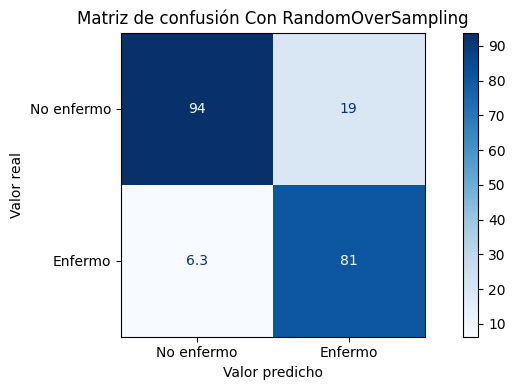

Reporte de la clasificación
              precision    recall  f1-score   support

           0      0.937     0.931     0.934      1316
           1      0.807     0.823     0.815       462

    accuracy                          0.903      1778
   macro avg      0.872     0.877     0.874      1778
weighted avg      0.903     0.903     0.903      1778

Reporte de clasificación desbalanceado
                   pre       rec       spe        f1       geo       iba       sup

 No enfermo       0.94      0.93      0.82      0.93      0.88      0.77      1316
    Enfermo       0.81      0.82      0.93      0.81      0.88      0.76       462

avg / total       0.90      0.90      0.85      0.90      0.88      0.77      1778



In [33]:
y_pred = modelos["LGBM_ros_best"].predict(X_test)
mostrar_resultados(y_test, y_pred, "Con RandomOverSampling")

Test balanced accuracy: 0.8880445795339412
 Trace 170.21823403796216
 Matriz de confusión


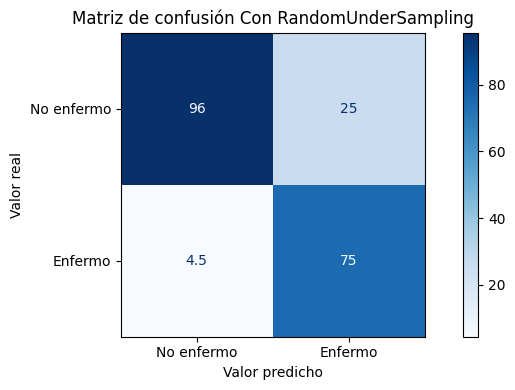

Reporte de la clasificación
              precision    recall  f1-score   support

           0      0.955     0.895     0.924      1316
           1      0.747     0.881     0.808       462

    accuracy                          0.891      1778
   macro avg      0.851     0.888     0.866      1778
weighted avg      0.901     0.891     0.894      1778

Reporte de clasificación desbalanceado
                   pre       rec       spe        f1       geo       iba       sup

 No enfermo       0.96      0.90      0.88      0.92      0.89      0.79      1316
    Enfermo       0.75      0.88      0.90      0.81      0.89      0.79       462

avg / total       0.90      0.89      0.88      0.89      0.89      0.79      1778



In [34]:
y_pred = modelos["LGBM_rus_best"].predict(X_test)
mostrar_resultados(y_test, y_pred, "Con RandomUnderSampling")

 Macro-Averaged Mean Absolute Error ROS: 0.12331905682969513
 Macro-Averaged Mean Absolute Error NONE: 0.11108040895274937
 Macro-Averaged Mean Absolute Error RUS: 0.11195542046605876
 Macro-Averaged Mean Absolute Error SMOTENC: 0.12709542230818827


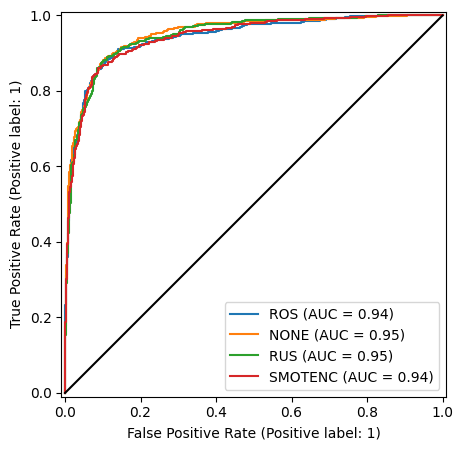

In [35]:
fig, ax = plt.subplots(figsize=(7, 5))
for nombre, model in modelos.items():
    if "LGBM" in nombre:
        nombre = nombre.split("_")[1].upper()
        RocCurveDisplay.from_estimator(model, X_test, y_test, name=nombre,ax = ax)
        y_pred = model.predict(X_test)
        print(f" Macro-Averaged Mean Absolute Error {nombre}: {macro_averaged_mean_absolute_error(y_test, y_pred)}")
ax.plot([0, 1], [0, 1], c="k")
ax.legend(loc="lower right")
plt.show()

## Adaboost

Test balanced accuracy: 0.8700953302017131
 Trace 165.17781495079402
 Matriz de confusión


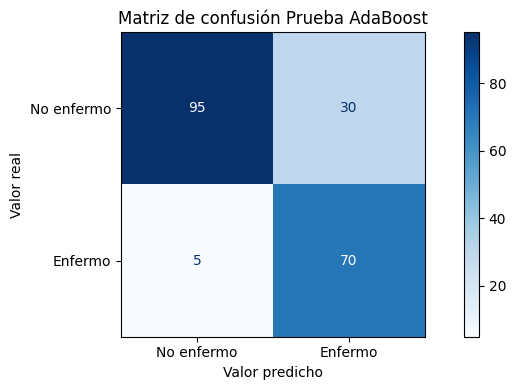

Reporte de la clasificación
              precision    recall  f1-score   support

           0      0.950     0.870     0.908      1316
           1      0.702     0.870     0.777       462

    accuracy                          0.870      1778
   macro avg      0.826     0.870     0.843      1778
weighted avg      0.886     0.870     0.874      1778

Reporte de clasificación desbalanceado
                   pre       rec       spe        f1       geo       iba       sup

 No enfermo       0.95      0.87      0.87      0.91      0.87      0.76      1316
    Enfermo       0.70      0.87      0.87      0.78      0.87      0.76       462

avg / total       0.89      0.87      0.87      0.87      0.87      0.76      1778



In [36]:
y_pred = modelos["AdaBoost_none_best"].predict(X_test)
mostrar_resultados(y_test, y_pred, "Prueba AdaBoost")

Test balanced accuracy: 0.868552546744036
 Trace 172.21569603771974
 Matriz de confusión


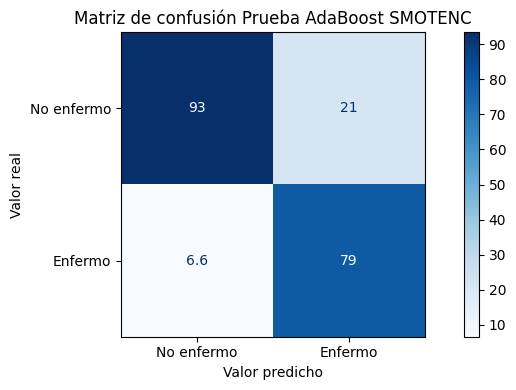

Reporte de la clasificación
              precision    recall  f1-score   support

           0      0.934     0.923     0.929      1316
           1      0.788     0.814     0.801       462

    accuracy                          0.895      1778
   macro avg      0.861     0.869     0.865      1778
weighted avg      0.896     0.895     0.895      1778

Reporte de clasificación desbalanceado
                   pre       rec       spe        f1       geo       iba       sup

 No enfermo       0.93      0.92      0.81      0.93      0.87      0.76      1316
    Enfermo       0.79      0.81      0.92      0.80      0.87      0.74       462

avg / total       0.90      0.89      0.84      0.90      0.87      0.76      1778



In [37]:
y_pred = modelos["AdaBoost_smotenc_best"].predict(X_test)

mostrar_resultados(y_test, y_pred, "Prueba AdaBoost SMOTENC")

Test balanced accuracy: 0.8609767891682785
 Trace 171.40054655475308
 Matriz de confusión


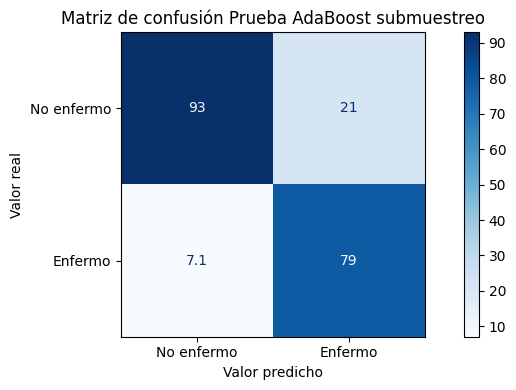

Reporte de la clasificación
              precision    recall  f1-score   support

           0      0.929     0.923     0.926      1316
           1      0.785     0.799     0.792       462

    accuracy                          0.891      1778
   macro avg      0.857     0.861     0.859      1778
weighted avg      0.892     0.891     0.891      1778

Reporte de clasificación desbalanceado
                   pre       rec       spe        f1       geo       iba       sup

 No enfermo       0.93      0.92      0.80      0.93      0.86      0.75      1316
    Enfermo       0.79      0.80      0.92      0.79      0.86      0.73       462

avg / total       0.89      0.89      0.83      0.89      0.86      0.74      1778



In [38]:
y_pred = modelos["AdaBoost_ros_best"].predict(X_test)
mostrar_resultados(y_test, y_pred, "Prueba AdaBoost submuestreo")

Test balanced accuracy: 0.8664686377452335
 Trace 164.65785544626573
 Matriz de confusión


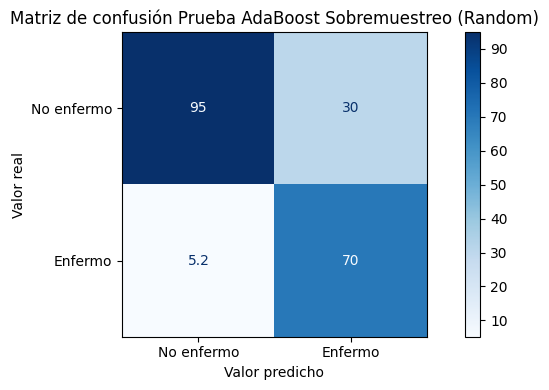

Reporte de la clasificación
              precision    recall  f1-score   support

           0      0.948     0.869     0.907      1316
           1      0.699     0.864     0.773       462

    accuracy                          0.868      1778
   macro avg      0.823     0.866     0.840      1778
weighted avg      0.883     0.868     0.872      1778

Reporte de clasificación desbalanceado
                   pre       rec       spe        f1       geo       iba       sup

 No enfermo       0.95      0.87      0.86      0.91      0.87      0.75      1316
    Enfermo       0.70      0.86      0.87      0.77      0.87      0.75       462

avg / total       0.88      0.87      0.87      0.87      0.87      0.75      1778



In [39]:
y_pred = modelos["AdaBoost_rus_best"].predict(X_test)
mostrar_resultados(y_test, y_pred, "Prueba AdaBoost Sobremuestreo (Random)")

## XGBoost

In [40]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

modelo = Pipeline([("preprocesar", preprocesador),
                   ("XGBoost", xgb.XGBClassifier(
                objective="binary:logistic",
                tree_method="hist",
                eval_metric="auc",
                scale_pos_weight=scale_pos_weight,
                random_state=42,
            ))])

modelo_inicial = modelo.fit(X_train, y_train)
y_pred = modelo.predict(X_test)


Test balanced accuracy: 0.8684949801971078
 Trace 171.82479318177081
 Matriz de confusión


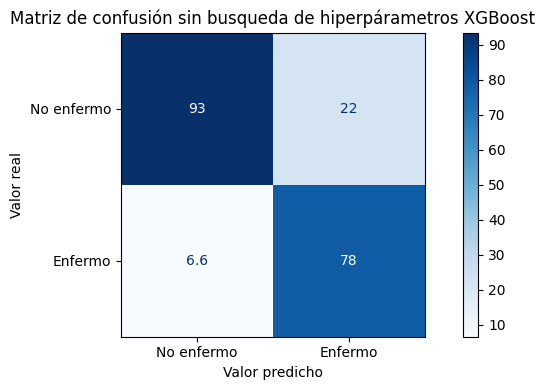

Reporte de la clasificación
              precision    recall  f1-score   support

           0      0.934     0.921     0.928      1316
           1      0.784     0.816     0.800       462

    accuracy                          0.894      1778
   macro avg      0.859     0.868     0.864      1778
weighted avg      0.895     0.894     0.894      1778

Reporte de clasificación desbalanceado
                   pre       rec       spe        f1       geo       iba       sup

 No enfermo       0.93      0.92      0.82      0.93      0.87      0.76      1316
    Enfermo       0.78      0.82      0.92      0.80      0.87      0.74       462

avg / total       0.90      0.89      0.84      0.89      0.87      0.76      1778



In [41]:
mostrar_resultados(y_test, y_pred, "sin busqueda de hiperpárametros XGBoost")

Test balanced accuracy: 0.8838652482269503
 Trace 168.7006205183153
 Matriz de confusión


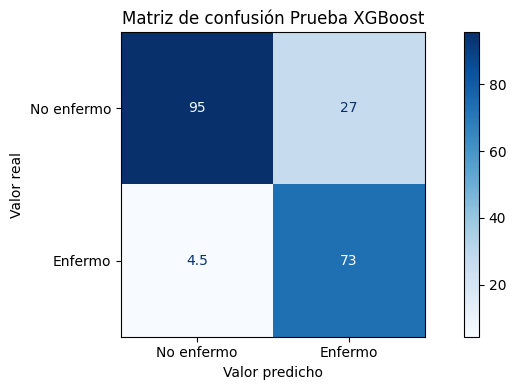

Reporte de la clasificación
              precision    recall  f1-score   support

           0      0.955     0.887     0.920      1316
           1      0.732     0.881     0.800       462

    accuracy                          0.885      1778
   macro avg      0.844     0.884     0.860      1778
weighted avg      0.897     0.885     0.888      1778

Reporte de clasificación desbalanceado
                   pre       rec       spe        f1       geo       iba       sup

 No enfermo       0.95      0.89      0.88      0.92      0.88      0.78      1316
    Enfermo       0.73      0.88      0.89      0.80      0.88      0.78       462

avg / total       0.90      0.89      0.88      0.89      0.88      0.78      1778



In [42]:
y_pred = modelos["XGBoost_none_best"].predict(X_test)
mostrar_resultados(y_test, y_pred, "Prueba XGBoost")

Test balanced accuracy: 0.8819540388689324
 Trace 163.8577242479239
 Matriz de confusión


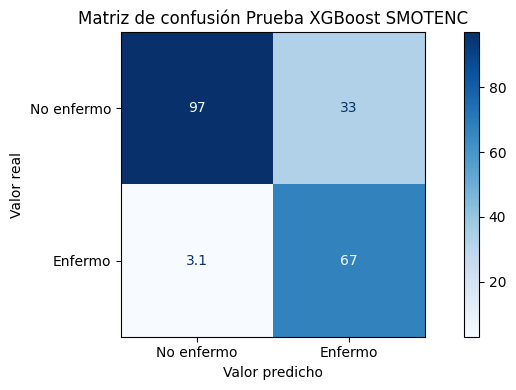

Reporte de la clasificación
              precision    recall  f1-score   support

           0      0.969     0.840     0.900      1316
           1      0.669     0.924     0.776       462

    accuracy                          0.862      1778
   macro avg      0.819     0.882     0.838      1778
weighted avg      0.891     0.862     0.868      1778

Reporte de clasificación desbalanceado
                   pre       rec       spe        f1       geo       iba       sup

 No enfermo       0.97      0.84      0.92      0.90      0.88      0.77      1316
    Enfermo       0.67      0.92      0.84      0.78      0.88      0.78       462

avg / total       0.89      0.86      0.90      0.87      0.88      0.77      1778



In [43]:
y_pred = modelos["XGBoost_smotenc_best"].predict(X_test)

mostrar_resultados(y_test, y_pred, "Prueba XGBoost SMOTENC")

Test balanced accuracy: 0.875
 Trace 168.4247250595348
 Matriz de confusión


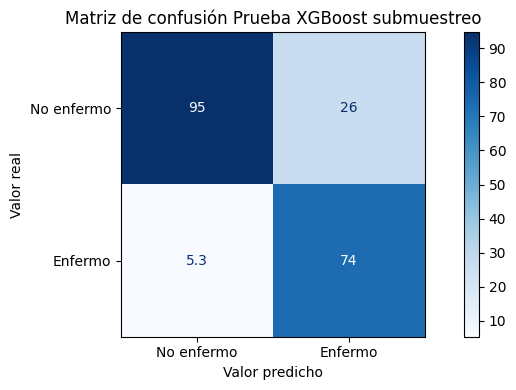

Reporte de la clasificación
              precision    recall  f1-score   support

           0      0.947     0.893     0.919      1316
           1      0.737     0.857     0.793       462

    accuracy                          0.884      1778
   macro avg      0.842     0.875     0.856      1778
weighted avg      0.892     0.884     0.886      1778

Reporte de clasificación desbalanceado
                   pre       rec       spe        f1       geo       iba       sup

 No enfermo       0.95      0.89      0.86      0.92      0.87      0.77      1316
    Enfermo       0.74      0.86      0.89      0.79      0.87      0.76       462

avg / total       0.89      0.88      0.87      0.89      0.87      0.77      1778



In [44]:
y_pred = modelos["XGBoost_ros_best"].predict(X_test)
mostrar_resultados(y_test, y_pred, "Prueba XGBoost submuestreo")

Test balanced accuracy: 0.8595721654232292
 Trace 157.39786809493802
 Matriz de confusión


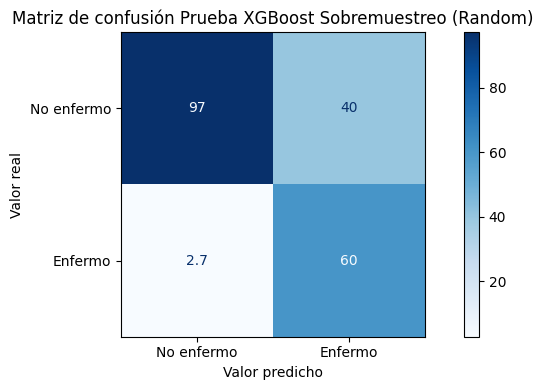

Reporte de la clasificación
              precision    recall  f1-score   support

           0      0.973     0.782     0.867      1316
           1      0.601     0.937     0.733       462

    accuracy                          0.822      1778
   macro avg      0.787     0.860     0.800      1778
weighted avg      0.876     0.822     0.832      1778

Reporte de clasificación desbalanceado
                   pre       rec       spe        f1       geo       iba       sup

 No enfermo       0.97      0.78      0.94      0.87      0.86      0.72      1316
    Enfermo       0.60      0.94      0.78      0.73      0.86      0.74       462

avg / total       0.88      0.82      0.90      0.83      0.86      0.73      1778



In [45]:
y_pred = modelos["XGBoost_rus_best"].predict(X_test)
mostrar_resultados(y_test, y_pred, "Prueba XGBoost Sobremuestreo (Random)")

 Macro-Averaged Mean Absolute Error RUS: 0.14042783457677074
 Macro-Averaged Mean Absolute Error ROS: 0.125
 Macro-Averaged Mean Absolute Error NONE: 0.11613475177304963
 Macro-Averaged Mean Absolute Error SMOTENC: 0.11804596113106752


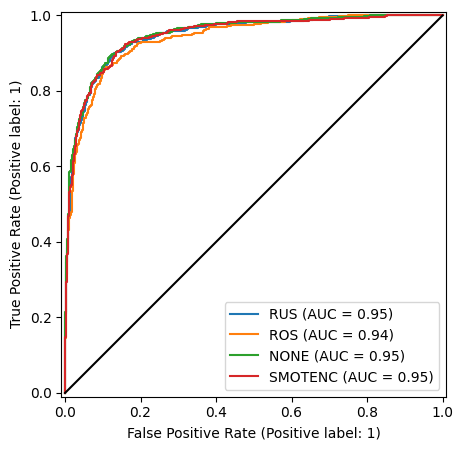

In [48]:
fig, ax = plt.subplots(figsize=(7, 5))
for nombre, model in modelos.items():
    if "XGBoost" in nombre:
        nombre = nombre.split("_")[1].upper()
        RocCurveDisplay.from_estimator(model, X_test, y_test, name=nombre,ax = ax)
        y_pred = model.predict(X_test)
        print(f" Macro-Averaged Mean Absolute Error {nombre}: {macro_averaged_mean_absolute_error(y_test, y_pred)}")
ax.plot([0, 1], [0, 1], c="k")
ax.legend(loc="lower right")
plt.show()

## Implementación AdaBoost

In [31]:
class Decision_stump(ClassifierMixin, BaseEstimator):
    def __init__(self):
        self.index_feature = 0
        self.best_threshold = 0
        self.polarity = 1

    def fit(self, X, y, sample_weight=None):
        '''fit with decision Stump'''
        X, y = check_X_y(X, y, accept_sparse=True)
        if hasattr(X, "toarray"):
            X = X.toarray()

        if hasattr(self, "is_fitted_"):
            del self.is_fitted_

        self.index_feature = 0
        self.best_threshold = 0
        self.polarity = 1

        self.classes_ = np.unique(y)

        min_error = np.inf

        if sample_weight is None:
            sample_weight = np.full(len(X), 1 / len(X))
            
        else:
            sample_weight = np.asarray(sample_weight, dtype=float)

            if sample_weight.shape != (len(X),):
                raise ValueError("Debe existir un peso por observación.")

            if not np.all(np.isfinite(sample_weight)) or np.any(sample_weight < 0) or not np.any(sample_weight > 0):
                raise ValueError("Los pesos deben ser finitos, no negativos y tener suma positiva.")

        for j in range(X.shape[1]):
            values = np.unique(X[:, j])
            thresholds = (values[:-1] + values[1:]) / 2

            for thr in thresholds:
                groups = X[:, j] > thr

                if groups.sum() == 0 or groups.sum() == len(X):
                    continue

                for polar in [0, 1]:
                    if polar == 1:
                        y_pred = groups.astype(int)
                    else:
                        y_pred = (~groups).astype(int)

                    mask = np.where(y != y_pred)
                    error = np.sum(sample_weight[mask])

                    if error < min_error:
                        min_error = error
                        self.best_threshold = thr
                        self.index_feature = j
                        self.polarity = polar

        self.n_features_in_ = X.shape[1]
        self.is_fitted_ = True
        return self

    def predict(self, X):
        '''Predict the class before train fit'''
        check_is_fitted(self, "is_fitted_")

        X = check_array(X, accept_sparse=True)
        if hasattr(X, "toarray"):
            X = X.toarray()

        if X.shape[1] != self.n_features_in_:
            raise ValueError("X debe tener el mismo número de características que en fit.")

        groups = X[:, self.index_feature] > self.best_threshold

        if self.polarity == 1:
            y_pred = groups.astype(int)
        else:
            y_pred = (~groups).astype(int)

        return y_pred
        
class AdaBoost(ClassifierMixin, BaseEstimator):

    def __init__(self, n_estimadores=100, unbalance=False, estimator=None):
        self.n_estimadores = n_estimadores
        self.unbalance = unbalance
        self.estimator = estimator

    def boost(self, X, y, weights, iboost):
        '''One step for AdaBoost by one estimator'''

        estimator = clone(self.estimator if self.estimator is not None else Decision_stump())
        estimator.fit(X, y, sample_weight=weights)

        ht = estimator.predict(X)

        mask = np.where(ht != y)

        εt = np.sum(weights[mask])

        if εt <= 0: # El modelo no tuvo fallas o hay pesos negativos
            self.estimators_.append(estimator)
            return weights, 1, 0

        if εt >= 1.0/2:
            if len(self.estimators_) == 0:
                raise ValueError("El clasificador base es peor que adivinar ")
            return None, None, None

        αt = 1/2 * np.log((1 - εt) / εt)

        if iboost != self.n_estimadores - 1: # Ultima ronda de estimadores

            y_signed = 2 * y.astype(float) - 1
            ht_signed = 2 * ht.astype(float) - 1
            weights *= np.exp(-αt * y_signed * ht_signed)
            weights /= np.sum(weights)

        self.estimators_.append(estimator)

        return weights, αt, εt

    def fit(self, X, y):
        '''Fit AdaBoost'''
        X, y = check_X_y(X, y, accept_sparse=True)
        if hasattr(X, "toarray"):
            X = X.toarray()

        if hasattr(self, "is_fitted_"):
            del self.is_fitted_

        self.classes_ = np.unique(y)

        self.n_features_in_ = X.shape[1]
        sample_weight = np.full(len(X), 1 / len(X))

        if self.unbalance: # Si la clase se encuentra desbalanceada

            p0, p1 = compute_class_weight(class_weight='balanced', classes=self.classes_, y=y)

            sample_weight = np.where(y == 1, p1, p0)
            sample_weight /= np.sum(sample_weight)

        self.estimators_ = []
        self.errors_ = np.ones(self.n_estimadores)
        self.alfas_ = np.zeros(self.n_estimadores)


        for iboost in tqdm.tqdm(range(self.n_estimadores), desc="N_estimadores"):

            sample_weight, αt, εt = self.boost(X, y, sample_weight, iboost)

            if sample_weight is None:
                break

            self.alfas_[iboost] = αt
            self.errors_[iboost] = εt

            if εt == 0:
                break

            Z = np.sum(sample_weight)

            if Z <= 0 or not np.isfinite(Z):
                raise ValueError("Pesos inválidos")

        self.alfas_ = self.alfas_[:len(self.estimators_)]
        self.errors_ = self.errors_[:len(self.estimators_)]
        self.is_fitted_ = True

        return self

    def predict(self, X):
        '''Predic AdaBoost after train with f(x) = Σ αt*ht(xi) '''

        check_is_fitted(self, "is_fitted_")
        X = check_array(X, accept_sparse=True)
        if hasattr(X, "toarray"):
            X = X.toarray()

        if X.shape[1] != self.n_features_in_:
            raise ValueError("X debe tener el mismo número de características que en fit.")

        predictions = np.array([estimator.predict(X) for estimator in self.estimators_])

        y_pred = []
        for row in predictions.T:
            f = np.sum(row * self.alfas_)
            if f > 1/2 * np.sum(self.alfas_):
                y_pred.append(1)
            else:
                y_pred.append(0)

        return np.asarray(y_pred)
    def decision_function(self, X):
        check_is_fitted(self, "is_fitted_")
    
        X = check_array(X, accept_sparse=True)
        if hasattr(X, "toarray"):
            X = X.toarray()
    
        if X.shape[1] != self.n_features_in_:
            raise ValueError(
                "X debe tener el mismo número de características que en fit.")
    
        predictions = np.array([estimator.predict(X) for estimator in self.estimators_])
    
        return np.sum(
            self.alfas_[:, np.newaxis] * (2 * predictions - 1),
            axis=0)

In [32]:
modelos_implementados = {}
model = Pipeline([("preprocesar", preprocesador),("AdaBoost", AdaBoost(n_estimadores=600, unbalance=True))])
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

modelos_implementados["None"] = model

N_estimadores: 100%|█████████████████████████| 600/600 [02:27<00:00,  4.06it/s]


Test balanced accuracy: 0.8701759233674127
 Trace 167.19210881429203
 Matriz de confusión


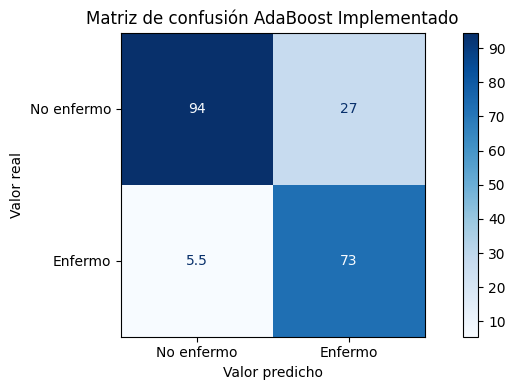

Reporte de la clasificación
              precision    recall  f1-score   support

           0      0.945     0.888     0.915      1316
           1      0.727     0.853     0.785       462

    accuracy                          0.879      1778
   macro avg      0.836     0.870     0.850      1778
weighted avg      0.888     0.879     0.881      1778

Reporte de clasificación desbalanceado
                   pre       rec       spe        f1       geo       iba       sup

 No enfermo       0.94      0.89      0.85      0.92      0.87      0.76      1316
    Enfermo       0.73      0.85      0.89      0.78      0.87      0.75       462

avg / total       0.89      0.88      0.86      0.88      0.87      0.76      1778



In [33]:
mostrar_resultados(y_test, y_pred, "AdaBoost Implementado")

In [38]:

X_resampled, y_resampled = SMOTENC(categorical_features=X_train.select_dtypes(exclude="number").columns.tolist(), sampling_strategy=1, random_state=42).fit_resample(X_train, y_train)
model = Pipeline([("preprocesar", preprocesador),("AdaBoost", AdaBoost(n_estimadores=600))])
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
modelos_implementados["smotenc"] = model

N_estimadores: 100%|█████████████████████████| 600/600 [02:28<00:00,  4.04it/s]


Test balanced accuracy: 0.8453762549507231
 Trace 174.74979397939262
 Matriz de confusión


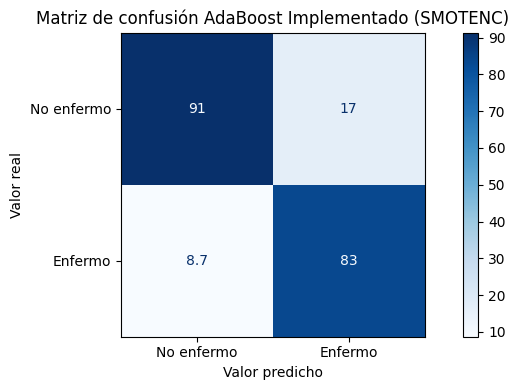

Reporte de la clasificación
              precision    recall  f1-score   support

           0      0.913     0.948     0.930      1316
           1      0.835     0.742     0.786       462

    accuracy                          0.895      1778
   macro avg      0.874     0.845     0.858      1778
weighted avg      0.893     0.895     0.893      1778

Reporte de clasificación desbalanceado
                   pre       rec       spe        f1       geo       iba       sup

 No enfermo       0.91      0.95      0.74      0.93      0.84      0.72      1316
    Enfermo       0.83      0.74      0.95      0.79      0.84      0.69       462

avg / total       0.89      0.89      0.80      0.89      0.84      0.71      1778



In [39]:
mostrar_resultados(y_test, y_pred, "AdaBoost Implementado (SMOTENC)")

In [40]:
X_resampled, y_resampled = RandomOverSampler(random_state=42).fit_resample(X_train, y_train)
model = Pipeline([("preprocesar", preprocesador),("AdaBoost", AdaBoost(n_estimadores=600))])
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
modelos_implementados["ros"] = model

N_estimadores: 100%|█████████████████████████| 600/600 [02:28<00:00,  4.05it/s]


Test balanced accuracy: 0.8453762549507231
 Trace 174.74979397939262
 Matriz de confusión


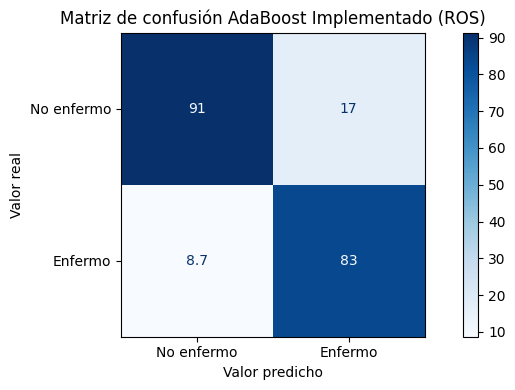

Reporte de la clasificación
              precision    recall  f1-score   support

           0      0.913     0.948     0.930      1316
           1      0.835     0.742     0.786       462

    accuracy                          0.895      1778
   macro avg      0.874     0.845     0.858      1778
weighted avg      0.893     0.895     0.893      1778

Reporte de clasificación desbalanceado
                   pre       rec       spe        f1       geo       iba       sup

 No enfermo       0.91      0.95      0.74      0.93      0.84      0.72      1316
    Enfermo       0.83      0.74      0.95      0.79      0.84      0.69       462

avg / total       0.89      0.89      0.80      0.89      0.84      0.71      1778



In [41]:
mostrar_resultados(y_test, y_pred, "AdaBoost Implementado (ROS)")

In [42]:
X_resampled, y_resampled = RandomUnderSampler(random_state=42).fit_resample(X_train, y_train)
model = Pipeline([("preprocesar", preprocesador),("AdaBoost", AdaBoost(n_estimadores=600))])
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
modelos_implementados["rus"] = model

NameError: name 'RandomUnderSampler' is not defined

In [ ]:
mostrar_resultados(y_test, y_pred, "AdaBoost Implementado (RUS)")

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))
for nombre, model in modelos_implementados.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=nombre.upper(),ax = ax)
    y_pred = model.predict(X_test)
    print(f" Macro-Averaged Mean Absolute Error {nombre}: {macro_averaged_mean_absolute_error(y_test, y_pred)}")
ax.plot([0, 1], [0, 1], c="k")
ax.legend(loc="lower right")
plt.show()